# Task 4: Motion Estimation

1. Frame differencing
2. GMM background subtraction
3. Lucas–Kanade optical flow
4. Visual comparison of motion detection methods

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

CURRENT_DIR = Path.cwd()
PROJECT_DIR = CURRENT_DIR.parent if CURRENT_DIR.name == "notebooks" else CURRENT_DIR

VIDEO_PATH = PROJECT_DIR / "data" / "videos" / "testvdo1.mp4"
OUTPUT_DIR = PROJECT_DIR / "outputs" / "task4_motion_estimation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise FileNotFoundError(f"Cannot open video: {VIDEO_PATH.resolve()}")

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

print("FPS:", fps)
print("Total frames:", total_frames)
print("Duration (seconds):", round(total_frames / fps, 2) if fps else "Unknown")

FPS: 29.993887885194784
Total frames: 247
Duration (seconds): 8.24


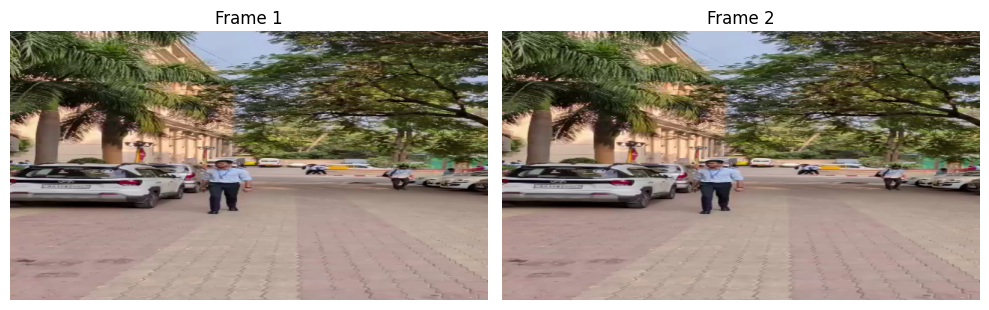

In [3]:
frames = []

# Read up to 100 frames for a manageable demonstration
while len(frames) < 100:
    ret, frame = cap.read()
    if not ret:
        break
    frames.append(cv2.resize(frame, (640, 360)))

cap.release()

if len(frames) < 2:
    raise ValueError("The video must contain at least two readable frames.")

frame1 = frames[0]
frame2 = frames[1]

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))
ax[0].set_title("Frame 1")
ax[1].imshow(cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB))
ax[1].set_title("Frame 2")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "01_consecutive_frames.png", dpi=150)
plt.show()

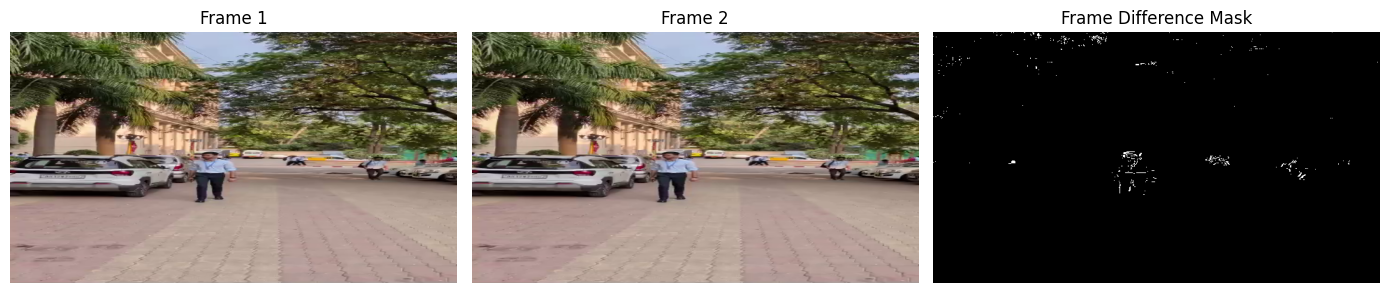

In [4]:
gray1 = cv2.cvtColor(frame1, cv2.COLOR_BGR2GRAY)
gray2 = cv2.cvtColor(frame2, cv2.COLOR_BGR2GRAY)

difference = cv2.absdiff(gray1, gray2)
_, diff_mask = cv2.threshold(difference, 25, 255, cv2.THRESH_BINARY)

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
ax[0].imshow(cv2.cvtColor(frame1, cv2.COLOR_BGR2RGB))
ax[0].set_title("Frame 1")
ax[1].imshow(cv2.cvtColor(frame2, cv2.COLOR_BGR2RGB))
ax[1].set_title("Frame 2")
ax[2].imshow(diff_mask, cmap="gray")
ax[2].set_title("Frame Difference Mask")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "02_frame_differencing.png", dpi=150)
plt.show()

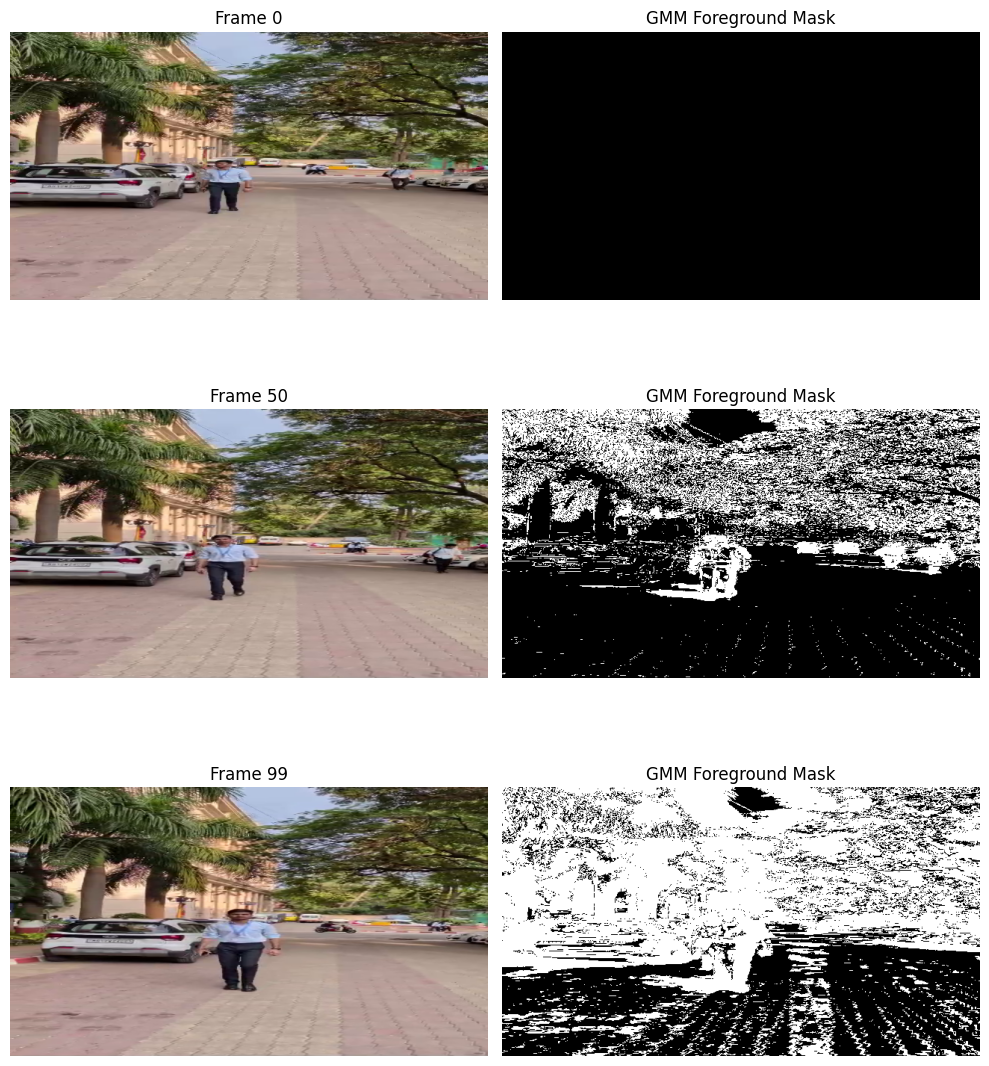

In [5]:
back_sub = cv2.createBackgroundSubtractorMOG2(
    history=100,
    varThreshold=25,
    detectShadows=False
)

selected_indices = sorted(set([
    0, len(frames) // 2, len(frames) - 1
]))

fig, ax = plt.subplots(len(selected_indices), 2,
                       figsize=(10, 4 * len(selected_indices)))
ax = np.atleast_2d(ax)

for row, idx in enumerate(selected_indices):
    frame = frames[idx]
    mask = back_sub.apply(frame)

    ax[row, 0].imshow(cv2.cvtColor(frame, cv2.COLOR_BGR2RGB))
    ax[row, 0].set_title(f"Frame {idx}")
    ax[row, 1].imshow(mask, cmap="gray")
    ax[row, 1].set_title("GMM Foreground Mask")

    ax[row, 0].axis("off")
    ax[row, 1].axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "03_gmm_background_subtraction.png", dpi=150)
plt.show()

Tracked feature points: 100


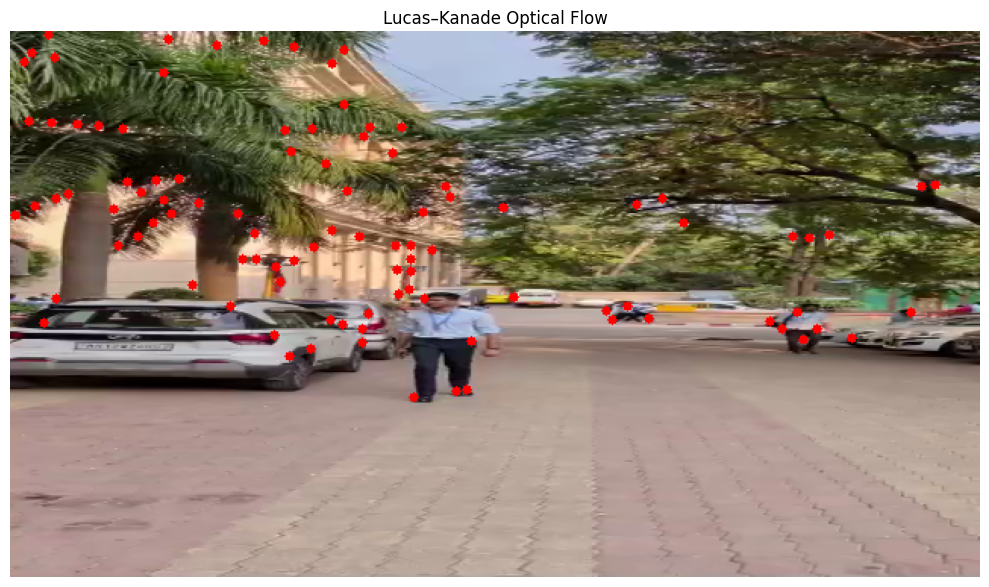

In [6]:
prev_gray = cv2.cvtColor(frames[0], cv2.COLOR_BGR2GRAY)
next_gray = cv2.cvtColor(frames[1], cv2.COLOR_BGR2GRAY)

points = cv2.goodFeaturesToTrack(
    prev_gray,
    maxCorners=100,
    qualityLevel=0.3,
    minDistance=7,
    blockSize=7
)

flow_result = frames[1].copy()

if points is not None:
    next_points, status, error = cv2.calcOpticalFlowPyrLK(
        prev_gray, next_gray, points, None
    )

    if next_points is not None:
        good_old = points[status.ravel() == 1]
        good_new = next_points[status.ravel() == 1]

        for old, new in zip(good_old, good_new):
            x1, y1 = old.ravel().astype(int)
            x2, y2 = new.ravel().astype(int)

            cv2.arrowedLine(
                flow_result, (x1, y1), (x2, y2),
                (0, 255, 0), 2, tipLength=0.3
            )
            cv2.circle(flow_result, (x2, y2), 3, (0, 0, 255), -1)

        print("Tracked feature points:", len(good_new))
    else:
        print("No feature points could be tracked.")
else:
    print("No suitable feature points found in the first frame.")

plt.figure(figsize=(10, 6))
plt.imshow(cv2.cvtColor(flow_result, cv2.COLOR_BGR2RGB))
plt.title("Lucas–Kanade Optical Flow")
plt.axis("off")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "04_lucas_kanade_optical_flow.png", dpi=150)
plt.show()

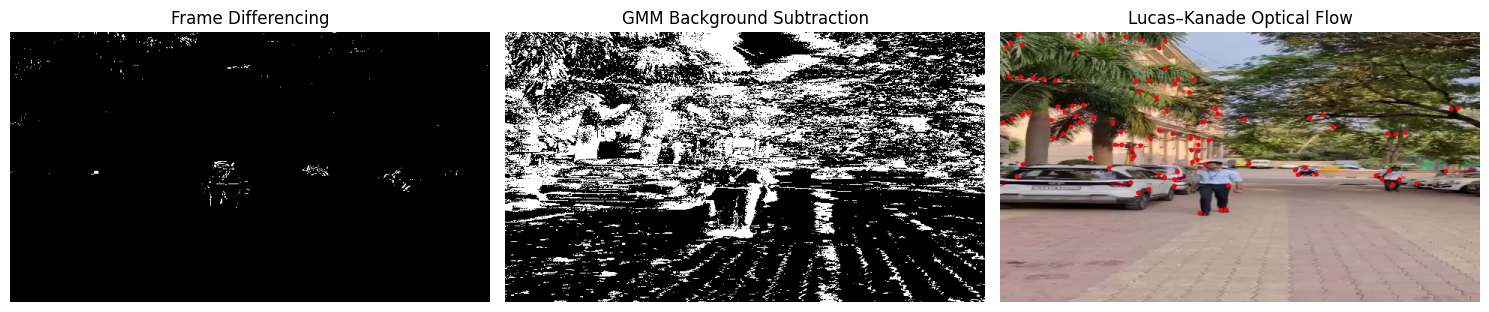

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

ax[0].imshow(diff_mask, cmap="gray")
ax[0].set_title("Frame Differencing")

# Use the final GMM mask displayed in Cell 5 only if you saved it separately.
# Recompute a mask for the last frame to make the comparison explicit.
gmm_model = cv2.createBackgroundSubtractorMOG2(
    history=100, varThreshold=25, detectShadows=False
)
gmm_mask = None
for frame in frames:
    gmm_mask = gmm_model.apply(frame)

ax[1].imshow(gmm_mask, cmap="gray")
ax[1].set_title("GMM Background Subtraction")

ax[2].imshow(cv2.cvtColor(flow_result, cv2.COLOR_BGR2RGB))
ax[2].set_title("Lucas–Kanade Optical Flow")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "05_motion_methods_comparison.png", dpi=150)
plt.show()

## Extra

In [8]:
from ultralytics import YOLO
import cv2
import matplotlib.pyplot as plt

model = YOLO("yolo11n.pt")

cap = cv2.VideoCapture(str(VIDEO_PATH))

if not cap.isOpened():
    raise FileNotFoundError(f"Cannot open video: {VIDEO_PATH}")

# Process every 10th frame to save time
frame_number = 0
sampled_frames = []
yolo_frames = []

while True:
    ret, frame = cap.read()
    if not ret:
        break

    if frame_number % 10 == 0:
        frame = cv2.resize(frame, (640, 360))

        results = model.predict(frame, conf=0.25, verbose=False)
        annotated = results[0].plot()

        sampled_frames.append(frame.copy())
        yolo_frames.append(annotated)

    frame_number += 1

cap.release()

print("Frames processed by YOLO:", len(yolo_frames))

Frames processed by YOLO: 25


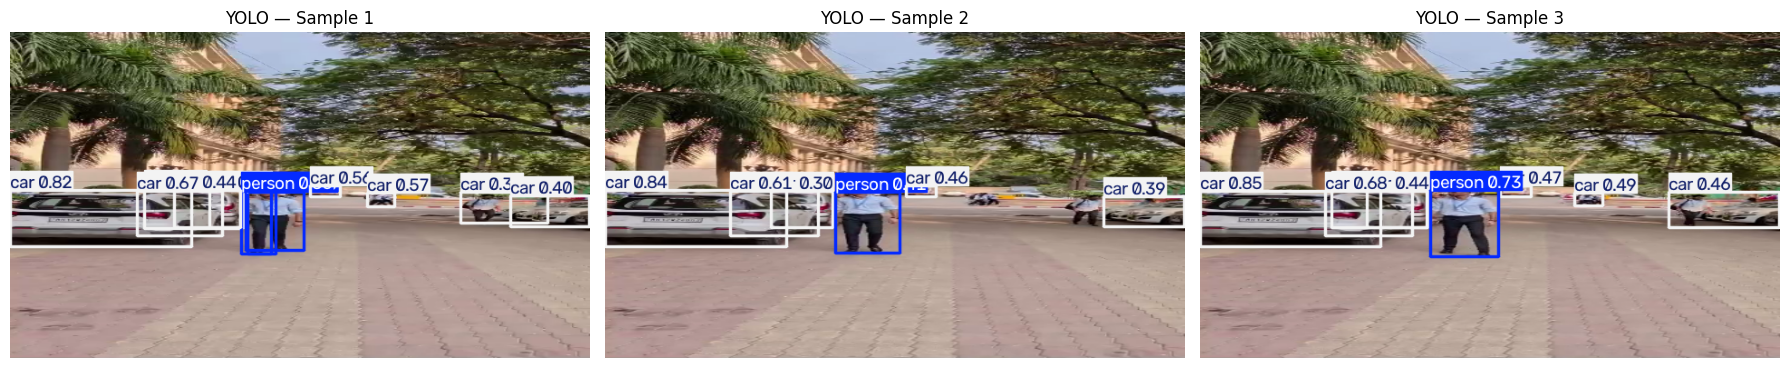

In [9]:
count = min(3, len(yolo_frames))

if count == 0:
    print("No frames were processed. Check your video file.")
else:
    fig, axes = plt.subplots(1, count, figsize=(6 * count, 4))
    if count == 1:
        axes = [axes]

    for i, ax in enumerate(axes):
        ax.imshow(cv2.cvtColor(yolo_frames[i], cv2.COLOR_BGR2RGB))
        ax.set_title(f"YOLO — Sample {i + 1}")
        ax.axis("off")

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "06_yolo_video_detection.png",
        dpi=150,
        bbox_inches="tight"
    )
    plt.show()

In [10]:
output_video = OUTPUT_DIR / "yolo_annotated_video.mp4"

if yolo_frames:
    height, width = yolo_frames[0].shape[:2]
    writer = cv2.VideoWriter(
        str(output_video),
        cv2.VideoWriter_fourcc(*"mp4v"),
        max(fps / 10, 1),
        (width, height)
    )

    for frame in yolo_frames:
        writer.write(frame)

    writer.release()
    print("Saved:", output_video)
else:
    print("No YOLO frames available to save.")

Saved: d:\Projects\CV\outputs\task4_motion_estimation\yolo_annotated_video.mp4
